# Bean Leaf Disease Detection: Model Notebook

**Problem.** Beans are a staple food and income source for farming households in Rwanda and across East Africa. Angular leaf spot and bean rust can reduce yields, and many farmers cannot get an expert to look at a sick plant quickly. This project classifies a phone photo of a bean leaf as **angular leaf spot**, **bean rust** or **healthy**.

**Data.** iBean, a set of real field photos collected in Uganda by the Makerere AI Lab with the National Crops Resources Research Institute. It is image data, published under the MIT license.

**This notebook covers:** data acquisition, preprocessing, feature interpretation, model creation, optimization, training, evaluation, and prediction. The same code in `src/` runs in the deployed API, so the notebook and the application process images the same way.

## 1. Setup

In [1]:
import hashlib
import json
import re
import sys
import urllib.request
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.metrics import auc, roc_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.model import SEED, build_model, compile_model, evaluate_model, fit_two_stage, list_images, make_dataset
from src.preprocessing import CLASSES, IMAGE_SIZE, INPUT_SHAPE, preprocess

DATA = ROOT / "data"
MODELS = ROOT / "models"
MODEL_PATH = MODELS / "bean_leaf_model.keras"
NAMES = {"angular_leaf_spot": "Angular leaf spot", "bean_rust": "Bean rust", "healthy": "Healthy"}
COLORS = {"angular_leaf_spot": "#2a78d6", "bean_rust": "#eb6834", "healthy": "#1baf7a"}

# Set to True to train the final model again. This replaces the saved model.
RUN_FULL_TRAINING = False

tf.keras.utils.set_random_seed(SEED)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.7,
    "axes.axisbelow": True, "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
})
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 2. Data acquisition

The cell below downloads the official train, validation and test splits only if they are missing. Keeping the publisher's splits means the test images stay separate from the start.

In [2]:
BASE_URL = "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data"

for split in ("train", "validation", "test"):
    if (DATA / split / CLASSES[0]).is_dir():
        print(f"{split}: already available")
        continue
    archive = DATA / f"{split}.zip"
    DATA.mkdir(exist_ok=True)
    urllib.request.urlretrieve(f"{BASE_URL}/{split}.zip", archive)
    with zipfile.ZipFile(archive) as bundle:
        bundle.extractall(DATA)
    archive.unlink()
    print(f"{split}: downloaded")

splits = {name: list_images(DATA / name) for name in ("train", "validation", "test")}
counts = pd.DataFrame({
    split: [labels.count(index) for index in range(len(CLASSES))] for split, (_, labels) in splits.items()
}, index=[NAMES[c] for c in CLASSES])
counts.loc["Total"] = counts.sum()
display(counts)

train: already available
validation: already available
test: already available


,train,validation,test
Angular leaf spot,345,44,43
Bean rust,348,45,43
Healthy,341,44,42
Total,1034,133,128


The classes are almost perfectly balanced in every split, so accuracy is meaningful and class weights are not needed for the first training run.

### Sample images

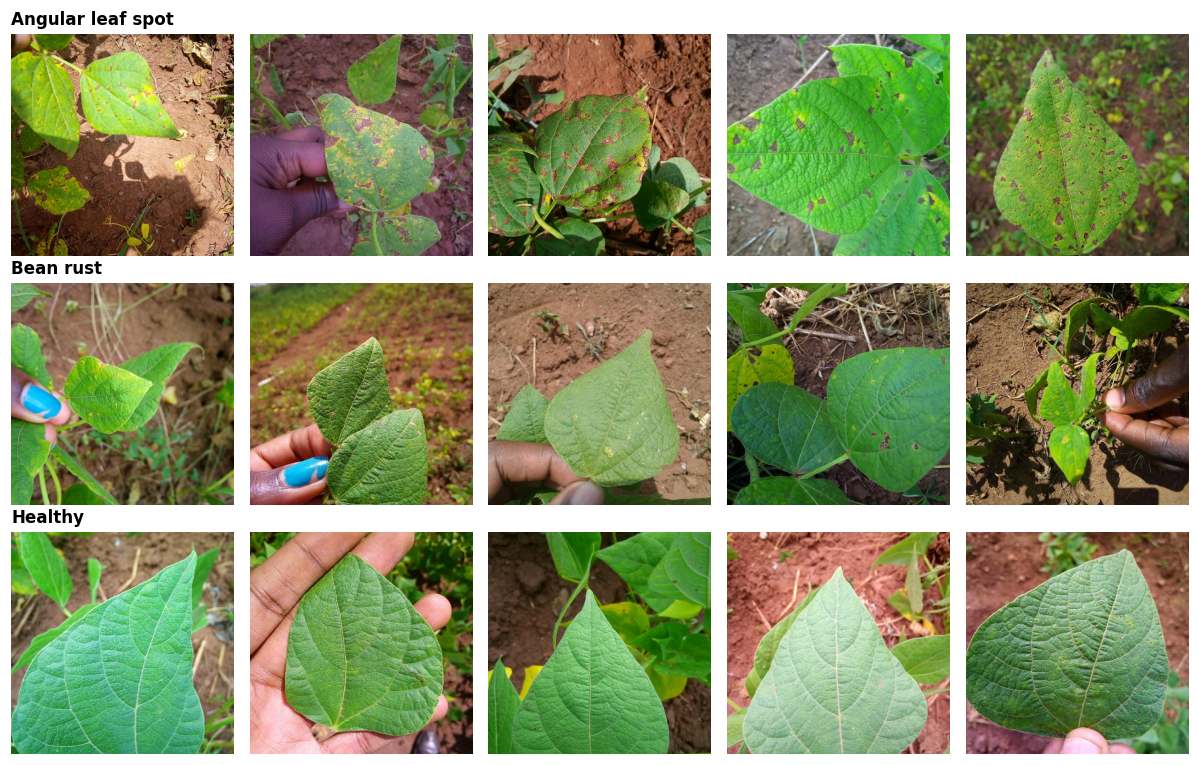

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for row, name in enumerate(CLASSES):
    files = sorted((DATA / "train" / name).glob("*.jpg"))[:5]
    for col, path in enumerate(files):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].axis("off")
    axes[row, 0].set_title(NAMES[name], loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### Data quality checks

Before training, I check that every file opens, look at image sizes, and search for exact duplicates. A duplicate shared between training and test would make the test score look better than it really is.

In [4]:
hashes, sizes, unreadable = defaultdict(list), Counter(), []
for split, (paths, _) in splits.items():
    for path in paths:
        try:
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                sizes[image.size] += 1
            hashes[hashlib.sha256(Path(path).read_bytes()).hexdigest()].append((split, path))
        except Exception:
            unreadable.append(path)

groups = [items for items in hashes.values() if len(items) > 1]
across = [items for items in groups if len({split for split, _ in items}) > 1]
print("Images checked:", sum(len(p) for p, _ in splits.values()))
print("Unreadable files:", len(unreadable))
print("Image sizes:", dict(sizes))
print("Exact duplicate groups:", len(groups))
print("Duplicates shared across splits:", len(across))

Images checked: 1295
Unreadable files: 0
Image sizes: {(500, 500): 1295}
Exact duplicate groups: 0
Duplicates shared across splits: 0


## 3. Preprocessing

Every image follows the same steps in training, in this notebook and in the API (`src/preprocessing.py`):

| Step | What happens | Why |
|---|---|---|
| 1. Decode and correct rotation | Reads the file and applies its EXIF rotation | Phone photos are often stored sideways |
| 2. Convert to RGB | Forces 3 colour channels | PNGs can have transparency or a single channel |
| 3. Resize | 224 x 224 pixels | The input size MobileNetV2 expects |
| 4. Convert to float | Values stay between 0 and 255 | Prepares the array for the model |
| 5. Augment (training only) | Random flip, rotation, zoom and contrast | Helps the model handle new photos and reduces overfitting |
| 6. Scale | Maps pixels to the range -1 to 1 | The range MobileNetV2 was trained on |

Steps 5 and 6 are layers inside the model. Saving them with the model means the API can never apply the wrong scaling.

Original size: (500, 500) mode: RGB
Array shape after preprocessing: (224, 224, 3) type: float32
Pixel range before scaling: 0 to 233
Pixel range after scaling: -1.00 to 0.83


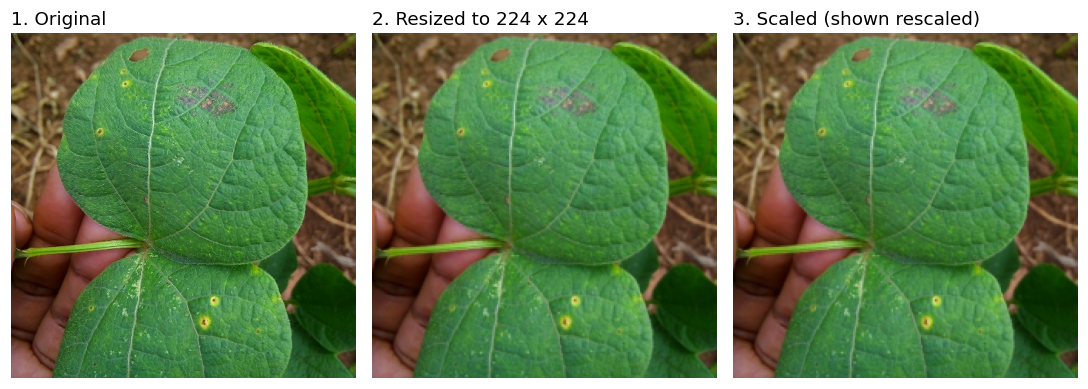

In [5]:
sample = sorted((DATA / "train" / "bean_rust").glob("*.jpg"))[10]
original = Image.open(sample)
upright = ImageOps.exif_transpose(original).convert("RGB")
array = preprocess(sample)
scaled = array / 127.5 - 1

print("Original size:", original.size, "mode:", original.mode)
print("Array shape after preprocessing:", array.shape, "type:", array.dtype)
print(f"Pixel range before scaling: {array.min():.0f} to {array.max():.0f}")
print(f"Pixel range after scaling: {scaled.min():.2f} to {scaled.max():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for axis, image, title in zip(axes, (upright, array.astype("uint8"), (scaled + 1) / 2),
                              ("1. Original", "2. Resized to 224 x 224", "3. Scaled (shown rescaled)")):
    axis.imshow(image)
    axis.set_title(title, loc="left")
    axis.axis("off")
plt.tight_layout()
plt.show()

### Data augmentation

These are eight random versions of the same training image. The model sees a slightly different version every epoch.

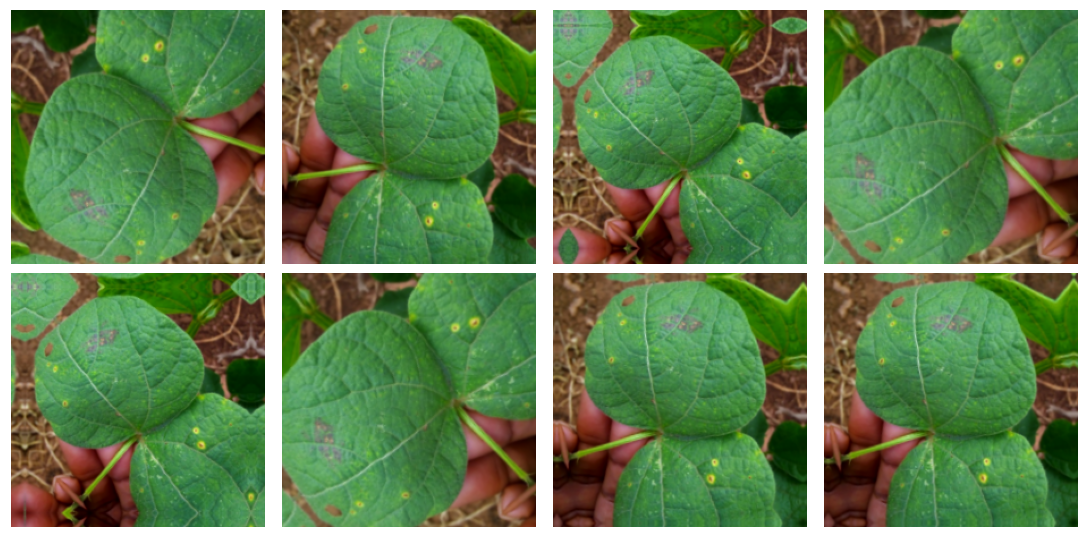

In [6]:
model = tf.keras.models.load_model(MODEL_PATH)
augment = model.get_layer("augmentation")
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for axis in axes.ravel():
    augmented = augment(array[np.newaxis], training=True)[0].numpy()
    axis.imshow(np.clip(augmented, 0, 255).astype("uint8"))
    axis.axis("off")
plt.tight_layout()
plt.show()

## 4. Feature interpretation: what story does the data tell?

Soil is brown like a lesion, so `src/insights.py` first isolates the main leaf and only measures inside it. The mask is approximate, so these features describe patterns across many leaves rather than single photos. Each chart shows how the leaves of a class are spread across one feature.

Measured 1031 of 1034 training images


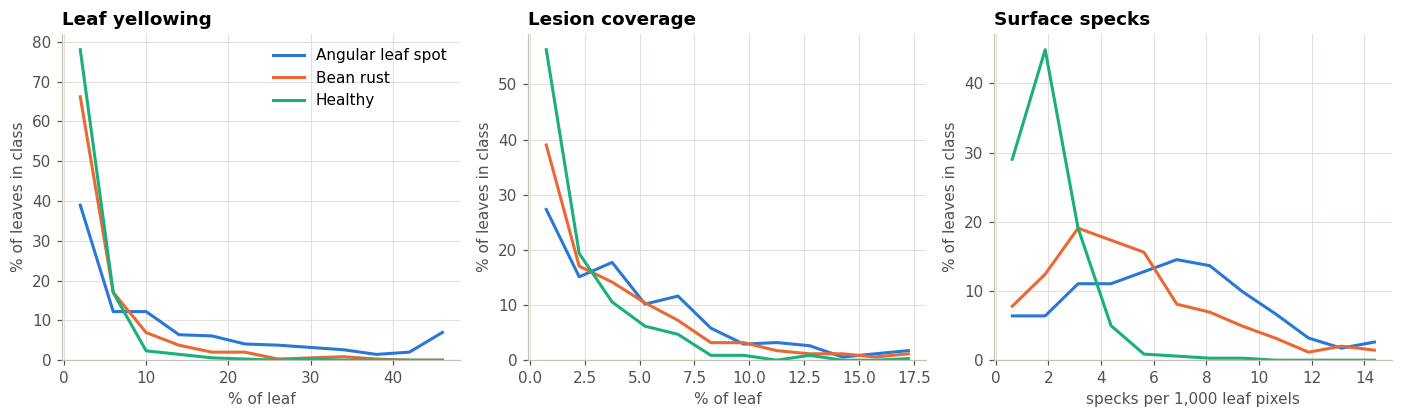

,Leaf yellowing,Lesion coverage,Surface specks
Median,,,
Angular leaf spot,7.11,3.70,6.50
Bean rust,2.17,2.46,4.30
Healthy,1.53,1.14,1.77


In [7]:
insights = json.loads((MODELS / "insights.json").read_text())
print(f"Measured {insights['images_measured']} of {insights['images_total']} training images")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for axis, feature in zip(axes, insights["features"].values()):
    edges = np.array(feature["edges"])
    centers = (edges[:-1] + edges[1:]) / 2
    for name in CLASSES:
        axis.plot(centers, feature["classes"][name]["share_pct"], color=COLORS[name], linewidth=2, label=NAMES[name])
    axis.set_title(feature["title"], loc="left", fontweight="bold")
    axis.set_xlabel(feature["unit"])
    axis.set_ylabel("% of leaves in class")
    axis.set_ylim(bottom=0)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    feature["title"]: {NAMES[name]: feature["classes"][name]["median"] for name in CLASSES}
    for feature in insights["features"].values()
}).round(2)
summary.index.name = "Median"
display(summary)

In [8]:
from IPython.display import Markdown
for feature in insights["features"].values():
    display(Markdown(f"**{feature['title']}.** {feature['story']}"))

**Leaf yellowing.** A typical angular leaf spot leaf is 7.1% yellow, about 4.6 times a healthy leaf (1.5%). Bean rust stays close to healthy at 2.2%, so yellowing points to angular leaf spot but cannot detect rust by itself.

**Lesion coverage.** Brown damage covers 3.7% of a typical angular leaf spot leaf and 2.5% of a bean rust leaf, against 1.1% for healthy leaves. The two diseases overlap heavily here, which helps explain why they are the hardest pair for the model to separate.

**Surface specks.** Healthy leaves have about 1.8 small specks per 1,000 leaf pixels, compared with 4.3 for bean rust and 6.5 for angular leaf spot. Fine surface texture is the clearest of these three signals that a leaf is diseased, and it is the kind of detail a CNN can learn.

## 5. Model creation and optimization

The model uses **transfer learning** with MobileNetV2, a small network pre-trained on ImageNet. It suits this project because the dataset is small and the API must respond quickly on a CPU.

| Technique | Setting | Purpose |
|---|---|---|
| Pre-trained model | MobileNetV2 (ImageNet) | Reuses learned visual features on a small dataset |
| Data augmentation | Flip, rotation, zoom, contrast | Reduces overfitting |
| Dropout | 0.3 | Reduces overfitting |
| L2 regularization | 0.0001 on the classifier | Keeps weights small |
| Optimizer | Adam | Adapts the learning rate per weight |
| Two-stage learning rates | 0.001, then 0.00001 | Trains the head, then gently fine-tunes |
| Fine-tuning | Top 30 backbone layers, BatchNorm frozen | Adapts high-level features to leaf disease |
| Early stopping | Patience 4, restores best weights | Stops before overfitting |
| Reduce LR on plateau | Halves after 2 flat epochs | Makes finer progress late in training |
| Model checkpoint | Best validation loss overall | Keeps the best model from either stage |

In [9]:
model.summary(expand_nested=False)

Model: "bean_leaf_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scale (Rescaling)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ backbone (Functional)           │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (GlobalAveragePooling2D)   │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,290,955 (20.18 MB)

 Trainable params: 1,514,563 (5.78 MB)

 Non-trainable params: 747,264 (2.85 MB)

 Optimizer params: 3,029,128 (11.56 MB)

## 6. Model training

### Baseline without optimization

To measure what the optimization added, I first train a plain version: the same frozen MobileNetV2 and classifier, with no augmentation, dropout, L2, early stopping or fine-tuning.

In [10]:
def build_baseline():
    backbone = tf.keras.applications.MobileNetV2(input_shape=INPUT_SHAPE, include_top=False, weights="imagenet")
    backbone.trainable = False
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)(inputs)
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    outputs = tf.keras.layers.Dense(len(CLASSES), activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name="baseline")

tf.keras.utils.set_random_seed(SEED)
train_paths, train_labels = splits["train"]
val_paths, val_labels = splits["validation"]
test_paths, test_labels = splits["test"]
train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)

baseline = build_baseline()
compile_model(baseline, 1e-3)
baseline_history = baseline.fit(train_ds, validation_data=val_ds, epochs=8, verbose=2)

Epoch 1/8


33/33 - 4s - 135ms/step - accuracy: 0.5957 - loss: 0.8800 - val_accuracy: 0.7970 - val_loss: 0.5608


Epoch 2/8


33/33 - 3s - 82ms/step - accuracy: 0.8337 - loss: 0.4609 - val_accuracy: 0.8571 - val_loss: 0.4306


Epoch 3/8


33/33 - 3s - 82ms/step - accuracy: 0.8810 - loss: 0.3551 - val_accuracy: 0.8722 - val_loss: 0.3763


... (6 outputs left out)

Epoch 7/8


33/33 - 3s - 81ms/step - accuracy: 0.9371 - loss: 0.2092 - val_accuracy: 0.8722 - val_loss: 0.3180


Epoch 8/8


33/33 - 3s - 83ms/step - accuracy: 0.9371 - loss: 0.1974 - val_accuracy: 0.9173 - val_loss: 0.2797


### Final optimized model

`RUN_FULL_TRAINING` is off by default so that running this notebook does not replace the deployed model. The cell then prints the saved log from the run that produced `models/bean_leaf_model.keras`. Set it to `True` to train again with the same code.

In [11]:
if RUN_FULL_TRAINING:
    tf.keras.utils.set_random_seed(SEED)
    final = build_model()
    history = fit_two_stage(final, train_ds, val_ds, MODEL_PATH)
    (MODELS / "history.json").write_text(json.dumps(history, indent=2))
    model = tf.keras.models.load_model(MODEL_PATH)
else:
    log = (ROOT / "logs" / "train_v1.log").read_text().splitlines()
    print("\n".join(line for line in log if line.startswith("Epoch") or "val_loss" in line))

history = json.loads((MODELS / "history.json").read_text())
head_epochs = 12
best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"\nEpochs run: {len(history['loss'])}. Best validation loss: {min(history['val_loss']):.4f} at epoch {best_epoch}.")

Epoch 1/12
33/33 - 5s - 160ms/step - accuracy: 0.5948 - loss: 0.9046 - val_accuracy: 0.7820 - val_loss: 0.5461 - learning_rate: 1.0000e-03
Epoch 2/12
33/33 - 3s - 102ms/step - accuracy: 0.7621 - loss: 0.5900 - val_accuracy: 0.8195 - val_loss: 0.4503 - learning_rate: 1.0000e-03
Epoch 3/12
33/33 - 3s - 101ms/step - accuracy: 0.7911 - loss: 0.4827 - val_accuracy: 0.8421 - val_loss: 0.3949 - learning_rate: 1.0000e-03
Epoch 4/12
33/33 - 3s - 100ms/step - accuracy: 0.8298 - loss: 0.4362 - val_accuracy: 0.8722 - val_loss: 0.3495 - learning_rate: 1.0000e-03
Epoch 5/12
33/33 - 3s - 101ms/step - accuracy: 0.8559 - loss: 0.3793 - val_accuracy: 0.8571 - val_loss: 0.3294 - learning_rate: 1.0000e-03
Epoch 6/12
33/33 - 3s - 99ms/step - accuracy: 0.8424 - loss: 0.3772 - val_accuracy: 0.8797 - val_loss: 0.3074 - learning_rate: 1.0000e-03
Epoch 7/12
33/33 - 3s - 101ms/step - accuracy: 0.8598 - loss: 0.3624 - val_accuracy: 0.8872 - val_loss: 0.3062 - learning_rate: 1.0000e-03
Epoch 8/12
33/33 - 3s - 100m

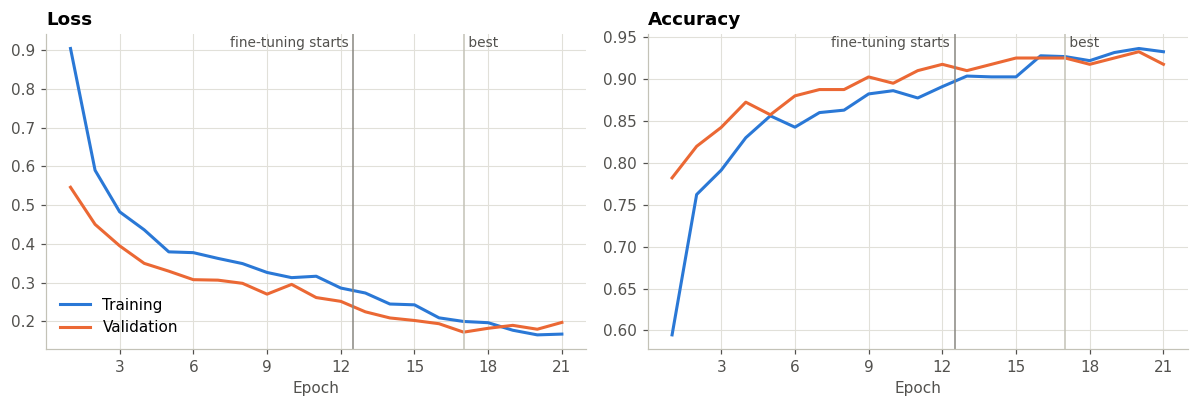

In [12]:
epochs = np.arange(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for axis, key, title in ((axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")):
    axis.plot(epochs, history[key], color="#2a78d6", linewidth=2, label="Training")
    axis.plot(epochs, history[f"val_{key}"], color="#eb6834", linewidth=2, label="Validation")
    axis.axvline(head_epochs + 0.5, color="#898781", linewidth=1)
    axis.annotate("fine-tuning starts ", (head_epochs + 0.5, 0.96), xycoords=("data", "axes fraction"), color="#52514e", fontsize=9, ha="right")
    axis.axvline(best_epoch, color="#c3c2b7", linewidth=1)
    axis.annotate(" best", (best_epoch, 0.96), xycoords=("data", "axes fraction"), color="#52514e", fontsize=9)
    axis.set_xticks(range(3, len(epochs) + 1, 3))
    axis.set_title(title, loc="left", fontweight="bold")
    axis.set_xlabel("Epoch")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

Validation loss keeps falling after fine-tuning starts, and training stopped early once it no longer improved. The model saved is the one from the best epoch, marked by the lighter vertical line.

## 7. Model evaluation

All final numbers come from the **test set**, which played no part in training or in choosing the model. I report seven metrics because accuracy alone hides which disease is being missed.

In [13]:
final_val = evaluate_model(model, val_paths, val_labels)
final_test = evaluate_model(model, test_paths, test_labels)
baseline_test = evaluate_model(baseline, test_paths, test_labels)
baseline_val = evaluate_model(baseline, val_paths, val_labels)

LABELS = {"accuracy": "Accuracy", "loss": "Loss", "precision_macro": "Precision (macro)", "recall_macro": "Recall (macro)",
          "f1_macro": "F1 score (macro)", "roc_auc_ovr": "ROC-AUC (one vs rest)", "cohen_kappa": "Cohen's kappa"}
table = pd.DataFrame({
    "Baseline (validation)": {LABELS[k]: baseline_val[k] for k in LABELS},
    "Final (validation)": {LABELS[k]: final_val[k] for k in LABELS},
    "Baseline (test)": {LABELS[k]: baseline_test[k] for k in LABELS},
    "Final (test)": {LABELS[k]: final_test[k] for k in LABELS},
}).round(4)
display(table)

,Baseline (validation),Final (validation),Baseline (test),Final (test)
Accuracy,0.9173,0.9248,0.8906,0.9062
Loss,0.2797,0.1710,0.3015,0.2352
Precision (macro),0.9174,0.9280,0.8977,0.9111
Recall (macro),0.9178,0.9247,0.8913,0.9066
F1 score (macro),0.9171,0.9257,0.8888,0.9065
ROC-AUC (one vs rest),0.9774,0.9915,0.9774,0.9856
Cohen's kappa,0.8760,0.8872,0.8360,0.8594


### Baseline against the optimized model

On the test set, the optimized model got 116 of 128 images right and the baseline got 114. That is 90.6% against 89.1%, a difference of only two images, so I do not treat the accuracy gain alone as proof that one model is better.

The clearer improvement is in the quality of the probabilities. Test loss fell from 0.302 to 0.235 and ROC-AUC rose from 0.977 to 0.986, so the optimized model ranks and scores its predictions more reliably. Validation shows the same pattern, with loss falling from 0.280 to 0.171.

### Per-class results

In [14]:
per_class = pd.DataFrame({NAMES[c]: final_test["per_class"][c] for c in CLASSES}).T
per_class = per_class.rename(columns={"f1-score": "f1"}).astype({"support": int}).round(3)
display(per_class)

,precision,recall,f1,support
Angular leaf spot,0.837,0.953,0.891,43
Bean rust,0.921,0.814,0.864,43
Healthy,0.976,0.952,0.964,42


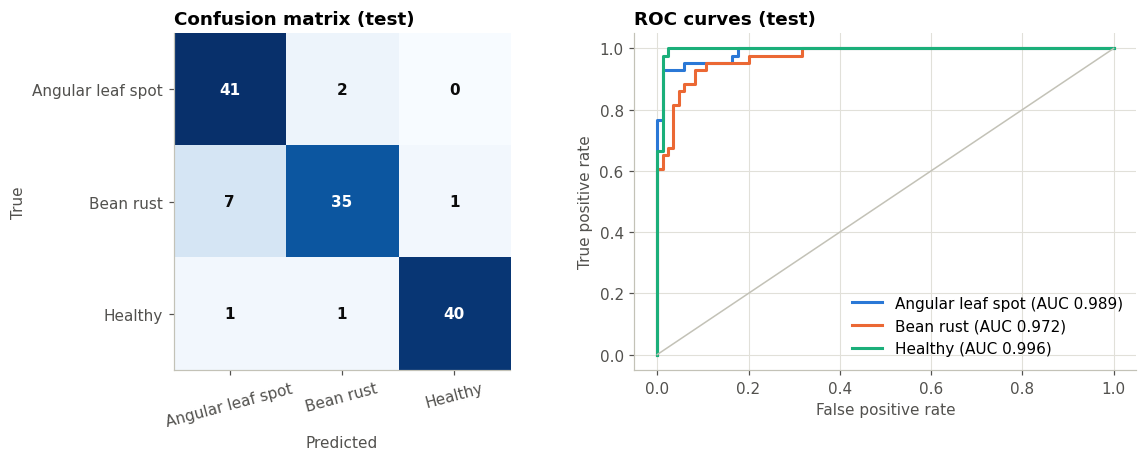

In [15]:
matrix = np.array(final_test["confusion_matrix"])
probabilities = model.predict(make_dataset(test_paths, test_labels), verbose=0)
y_true = np.array(test_labels)
y_pred = probabilities.argmax(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].imshow(matrix, cmap="Blues", vmin=0)
axes[0].grid(False)
ticks = [NAMES[c] for c in CLASSES]
axes[0].set_xticks(range(3), ticks, rotation=15)
axes[0].set_yticks(range(3), ticks)
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].set_title("Confusion matrix (test)", loc="left", fontweight="bold")
for row in range(3):
    for col in range(3):
        axes[0].text(col, row, matrix[row, col], ha="center", va="center",
                     color="white" if matrix[row, col] > matrix.max() / 2 else "#0b0b0b", fontweight="bold")

for index, name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_true == index, probabilities[:, index])
    axes[1].plot(fpr, tpr, color=COLORS[name], linewidth=2, label=f"{NAMES[name]} (AUC {auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curves (test)", loc="left", fontweight="bold")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation.** Healthy leaves are the easiest class (F1 0.964, AUC 0.996). Bean rust is the hardest (F1 0.864, AUC 0.972), with a recall of 0.814 because 7 of its 43 images were labelled angular leaf spot.

For a farmer, the most serious mistake is calling a sick plant healthy. That happened once: 85 of the 86 diseased test leaves were still flagged as diseased, even when the model picked the wrong disease. Only 2 of the 42 healthy leaves caused a false alarm.

### Error analysis

These are all the test images the model got wrong.

12 wrong out of 128


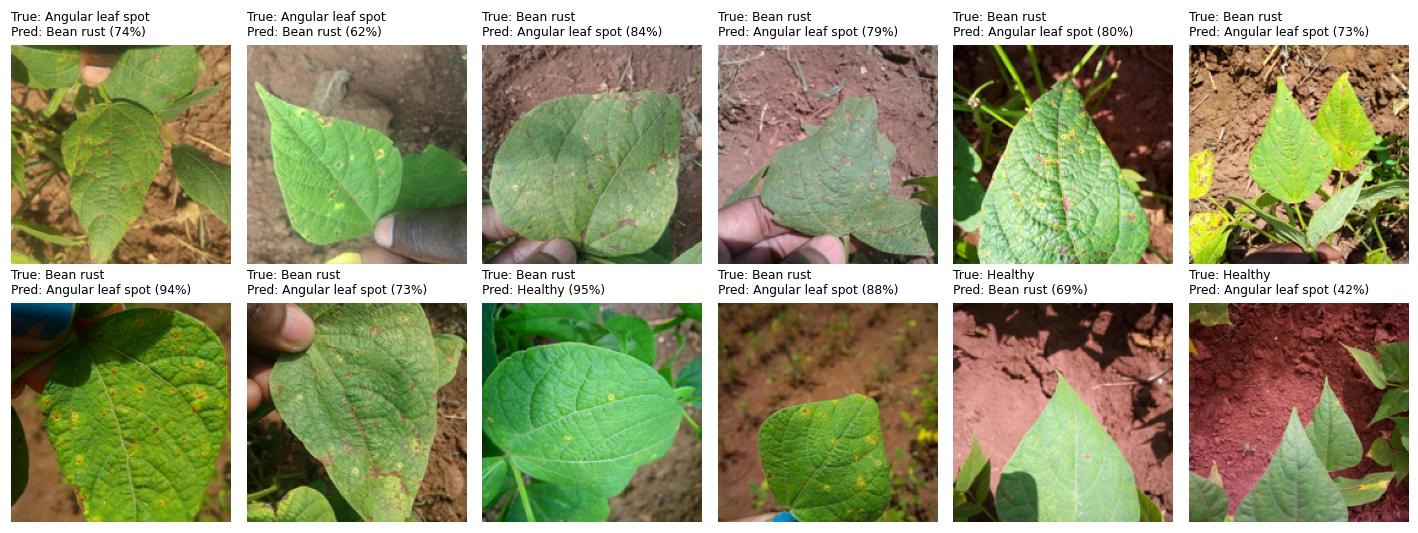

Median confidence when correct: 0.978
Median confidence when wrong: 0.768
Predictions below the app's 60% warning level: 5, of which wrong: 1


In [16]:
wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} wrong out of {len(y_true)}")
columns = 6
rows = int(np.ceil(len(wrong) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(13, 2.5 * rows), squeeze=False)
for axis in axes.ravel():
    axis.axis("off")
for axis, index in zip(axes.ravel(), wrong):
    axis.imshow(Image.open(test_paths[index]).resize((180, 180)))
    axis.set_title(f"True: {NAMES[CLASSES[y_true[index]]]}\nPred: {NAMES[CLASSES[y_pred[index]]]} ({probabilities[index].max():.0%})", fontsize=8, loc="left")
plt.tight_layout()
plt.show()

confidence = probabilities.max(axis=1)
correct = y_true == y_pred
print(f"Median confidence when correct: {np.median(confidence[correct]):.3f}")
print(f"Median confidence when wrong: {np.median(confidence[~correct]):.3f}")
print(f"Predictions below the app's 60% warning level: {(confidence < 0.6).sum()}, of which wrong: {((confidence < 0.6) & ~correct).sum()}")

**What the errors show.** Nine of the 12 mistakes are confusion between the two diseases, and seven of those are bean rust called angular leaf spot. Many of these rust leaves have brownish spots with yellow edges, which look close to angular leaf spot at this image size. The one rust leaf called healthy has only a few faint spots. Both healthy errors are photos where the leaf is only partly in frame and red soil fills much of the image.

Confidence is not a complete safety check. The app's 60% warning caught only 1 of the 12 mistakes, and the median confidence on wrong predictions was still 76.8%. More close-up bean rust images would be the most useful data to add in a future retraining round.

## 8. Model testing: prediction function

This function takes one image and returns the predicted class and confidence. The API uses the same preprocessing in `src/prediction.py`.

demo_angular_leaf_spot.jpg {'label': 'angular_leaf_spot', 'confidence': 0.9997777342796326, 'probabilities': {'angular_leaf_spot': 0.9998, 'bean_rust': 0.0002, 'healthy': 0.0}}
demo_bean_rust.jpg {'label': 'bean_rust', 'confidence': 0.9881888628005981, 'probabilities': {'angular_leaf_spot': 0.0034, 'bean_rust': 0.9882, 'healthy': 0.0084}}
demo_healthy.jpg {'label': 'healthy', 'confidence': 0.9946351647377014, 'probabilities': {'angular_leaf_spot': 0.0016, 'bean_rust': 0.0037, 'healthy': 0.9946}}


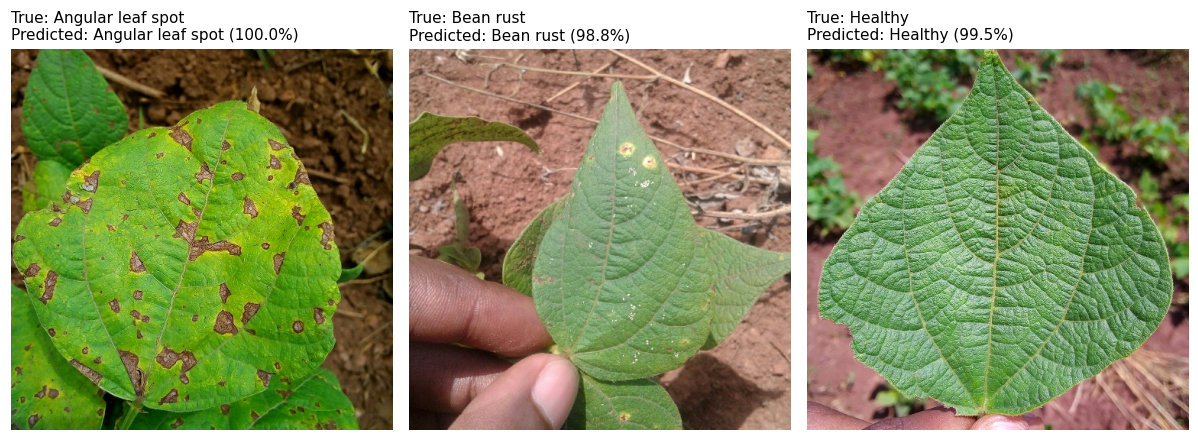

In [17]:
def predict_leaf(image_path, classifier=model):
    batch = preprocess(image_path)[np.newaxis]
    scores = classifier(batch, training=False).numpy()[0]
    index = int(scores.argmax())
    return {"label": CLASSES[index], "confidence": float(scores[index]),
            "probabilities": {name: round(float(p), 4) for name, p in zip(CLASSES, scores)}}

demo_images = {name: ROOT / "demo" / "predict" / f"demo_{name}.jpg" for name in CLASSES}
fig, axes = plt.subplots(1, 3, figsize=(11, 4.1))
for axis, (true_label, path) in zip(axes, demo_images.items()):
    result = predict_leaf(path)
    axis.imshow(Image.open(path))
    axis.axis("off")
    axis.set_title(f"True: {NAMES[true_label]}\nPredicted: {NAMES[result['label']]} ({result['confidence']:.1%})", loc="left", fontsize=10)
    print(path.name, result)
plt.tight_layout()
plt.show()

## 9. Retraining process

Retraining is in `src/retrain.py` and is started from the web dashboard or `POST /retrain`:

1. **Upload:** bulk images are validated and recorded in a SQLite database.
2. **Preprocess:** uploads go through the same preprocessing. Unreadable files and any image from the validation or test set are rejected.
3. **Retrain:** the model in service is loaded as the **pre-trained starting point**, then fine-tuned on the original training data plus the new images with a low learning rate.
4. **Compare:** the new model and the current model are scored on the same validation set.
5. **Promote:** the new version goes live only if its macro F1 is higher, or equal with a loss that is no worse. Otherwise the current version stays in service.

## 10. Conclusion and limitations

The final model reached **90.6% accuracy, 0.907 macro F1 and 0.986 ROC-AUC** on 128 unseen test images. It flagged 85 of the 86 diseased test leaves as diseased, and its main weakness is telling bean rust apart from angular leaf spot. It has these limits:

- All photos come from Ugandan fields, so performance on Rwandan farms should be checked with local images.
- The test set has only 128 images, so one image changes accuracy by about 0.8 percentage points.
- The model only knows three classes. A photo of something else will still receive one of these labels.
- It supports a farmer's decision and does not replace an agronomist.